# Análise de Dados de Conversas do WhatsApp

**Trabalho de Data Science — A2**

**Integrantes:**
- Integrante 1
- Integrante 2

Este notebook lê a exportação `.txt` de uma conversa em **grupo** do WhatsApp (Android ou iPhone, **sem mídia**), monta um `pandas.DataFrame` com as colunas **data**, **hora**, **remetente** e **mensagem** e oferece cinco análises:

| Requisito | Análise |
|-----------|---------|
| R4 | Resumo das conversas: total de mensagens por remetente |
| R5 | Histórico de um remetente (mensagens com data e hora) |
| R6 | Gráfico do histórico: mensagens por dia de cada remetente |
| R7 | Gráfico de pizza: percentual de mensagens por remetente |
| R8 | Gráfico de linhas: mensagens ao longo do tempo, uma cor por remetente |

### Como exportar a conversa

- **Android:** abra o grupo → menu **⋮** → **Mais** → **Exportar conversa** → **Sem mídia**.
- **iPhone:** abra o grupo → toque no nome do grupo → **Exportar conversa** → **Sem mídia**.

O WhatsApp gera um arquivo `.txt` (no iPhone, dentro de um `.zip`: extraia o `.txt`). Carregue-o pelo botão de upload abaixo ou ajuste a variável `CAMINHO`.

> Mensagens do sistema (ligações, notificações, avisos de criptografia) são ignoradas. Mídias omitidas e mensagens apagadas **contam** como mensagens.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from whatsapp_analise import ler_conversa, listar_remetentes, resumo_conversas, historico_remetente
from whatsapp_analise.graficos import grafico_historico_remetente, grafico_linhas, grafico_pizza
from whatsapp_analise.interface import (
    criar_painel, criar_upload, descrever_leitura, mostrar_figura, tabela_rolavel,
)

pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.dpi"] = 100

## 1. Carregar a conversa

Por padrão é lido o arquivo de exemplo anonimizado. Para analisar outra conversa, use o botão **Carregar .txt** (a tabela e o painel abaixo são atualizados) ou troque o `CAMINHO` e rode o notebook de novo (**Run All**), o que também atualiza as seções 4 a 8.

In [2]:
CAMINHO = "dados/exemplo_anonimizado.txt"

resultado = ler_conversa(CAMINHO)
df = resultado.df
print(descrever_leitura(resultado))



def carregar(novo):
    """Chamada pelo upload: troca a conversa e atualiza a tabela e o painel."""
    global resultado, df
    resultado, df = novo, novo.df
    saida_tabela.update(tabela_rolavel(df))
    saida_painel.update(criar_painel(df))


display(criar_upload(carregar))

Formato detectado: iPhone (datas em mês/dia)
Mensagens: 996
Remetentes: 10
Período: 29/09/2025 a 19/09/2026
Mensagens do sistema ignoradas: 7
Linhas antes da 1ª mensagem descartadas: 1


## 2. Tabela completa (R3)

Todas as mensagens (data, hora, remetente, mensagem), numa área com rolagem.

In [3]:
saida_tabela = display(tabela_rolavel(df), display_id=True)

,data,hora,remetente,mensagem
0,2025-09-29,12:41:32,Pessoa 1,<imagem ocultada> ficou muito bom
1,2025-09-29,12:41:40,Pessoa 1,fechou
2,2025-09-29,12:42:19,Pessoa 1,alguém vai hoje?
3,2025-09-29,12:42:28,Pessoa 1,vamos marcar sábado?
4,2025-09-29,12:42:36,Pessoa 1,isso aí
5,2025-09-29,12:42:37,Pessoa 1,hahahaha
6,2025-09-29,18:08:52,Pessoa 2,dmsss
7,2025-09-29,18:10:49,+55 00 0000-0003,vou ver aqui e já falo
8,2025-09-29,18:10:52,+55 00 0000-0003,chego em 10 min
9,2025-09-29,18:11:07,+55 00 0000-0003,quem leva o violão?


## 3. Painel interativo

Escolha a análise, o remetente (quando se aplica) e clique em **Executar**. O painel precisa de um kernel em execução; as seções seguintes mostram as mesmas análises direto nas células.

In [4]:
saida_painel = display(criar_painel(df), display_id=True)

## 4. Resumo das conversas (R4)

Remetentes ordenados do que mais enviou mensagens para o que menos enviou.

In [5]:
resumo_conversas(df)

,remetente,total_mensagens,percentual
1,Pessoa 1,434,43.6
2,+55 00 0000-0001,206,20.7
3,Pessoa 2,110,11.0
4,+55 00 0000-0002,82,8.2
5,Pessoa 3,56,5.6
6,Você,44,4.4
7,+55 00 0000-0003,35,3.5
8,+55 00 0000-0004,18,1.8
9,Pessoa 4,10,1.0
10,+55 00 0000-0005,1,0.1


## 5. Histórico do remetente (R5)

Mensagens de um remetente, com data e hora. Troque `REMETENTE` por qualquer nome da lista.

In [6]:
print("Remetentes:", listar_remetentes(df))
REMETENTE = listar_remetentes(df)[0]
historico = historico_remetente(df, REMETENTE)
print(f"{REMETENTE}: {len(historico)} mensagens")
tabela_rolavel(historico)

Remetentes: ['Pessoa 1', '+55 00 0000-0001', 'Pessoa 2', '+55 00 0000-0002', 'Pessoa 3', 'Você', '+55 00 0000-0003', '+55 00 0000-0004', 'Pessoa 4', '+55 00 0000-0005']
Pessoa 1: 434 mensagens


,data,hora,mensagem
0,2025-09-29,12:41:32,<imagem ocultada> ficou muito bom
1,2025-09-29,12:41:40,fechou
2,2025-09-29,12:42:19,alguém vai hoje?
3,2025-09-29,12:42:28,vamos marcar sábado?
4,2025-09-29,12:42:36,isso aí
5,2025-09-29,12:42:37,hahahaha
6,2025-09-29,18:21:56,amanhã eu posso
7,2025-09-29,18:22:32,alguém tem o link da aula?
8,2025-09-29,18:24:28,kkkkkk
9,2025-09-29,18:24:36,alguém vai hoje?


## 6. Gráfico do histórico do remetente (R6)

Quantidade de mensagens por dia, primeiro do remetente escolhido e depois de todos os remetentes, cada um no seu gráfico.

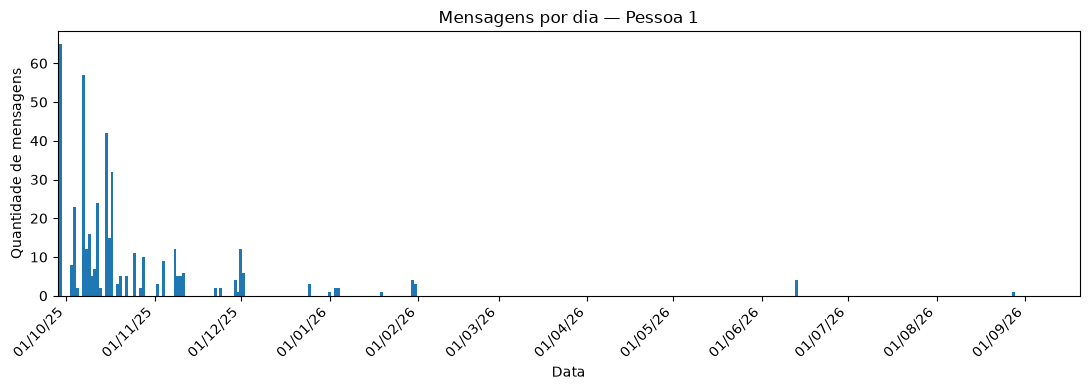

In [7]:
mostrar_figura(grafico_historico_remetente(df, REMETENTE))

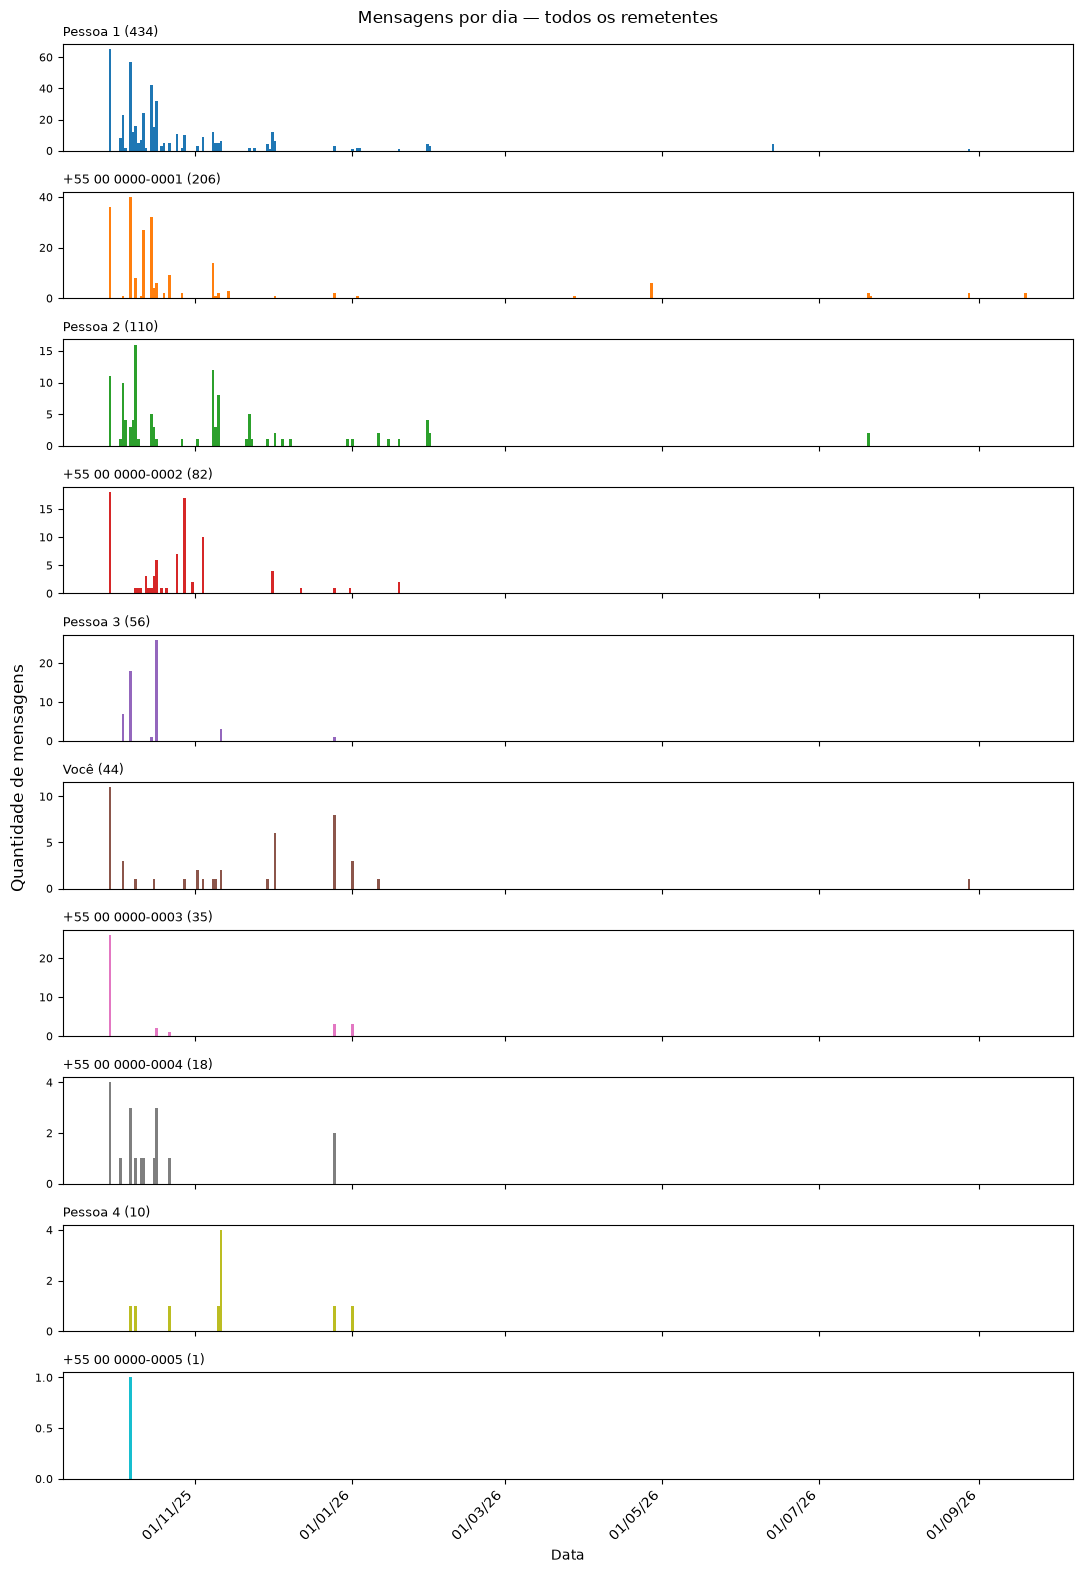

In [8]:
mostrar_figura(grafico_historico_remetente(df))

## 7. Gráfico de pizza (R7)

Percentual de mensagens de cada remetente. Fatias menores que 3 % não mostram o número dentro da fatia, mas o percentual de todos está na legenda.

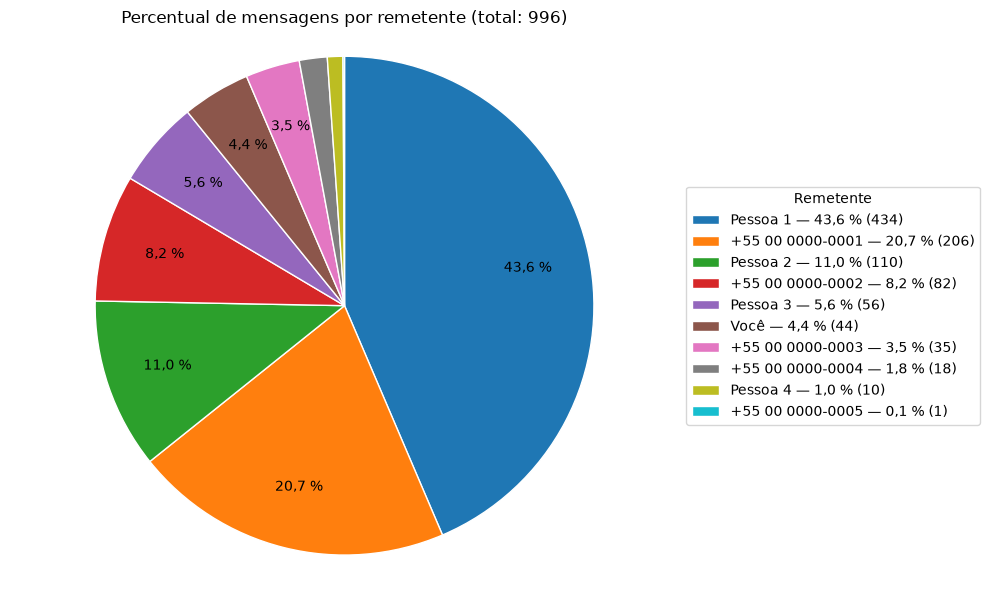

In [9]:
mostrar_figura(grafico_pizza(df))

## 8. Gráfico de linhas (R8)

Mensagens ao longo do tempo, todos os remetentes no mesmo gráfico, uma cor por remetente. Primeiro por **dia** (como pede o enunciado) e depois por **mês**, mais legível numa conversa longa. `freq` aceita `"D"` (dia), `"W"` (semana) e `"MS"` (mês).

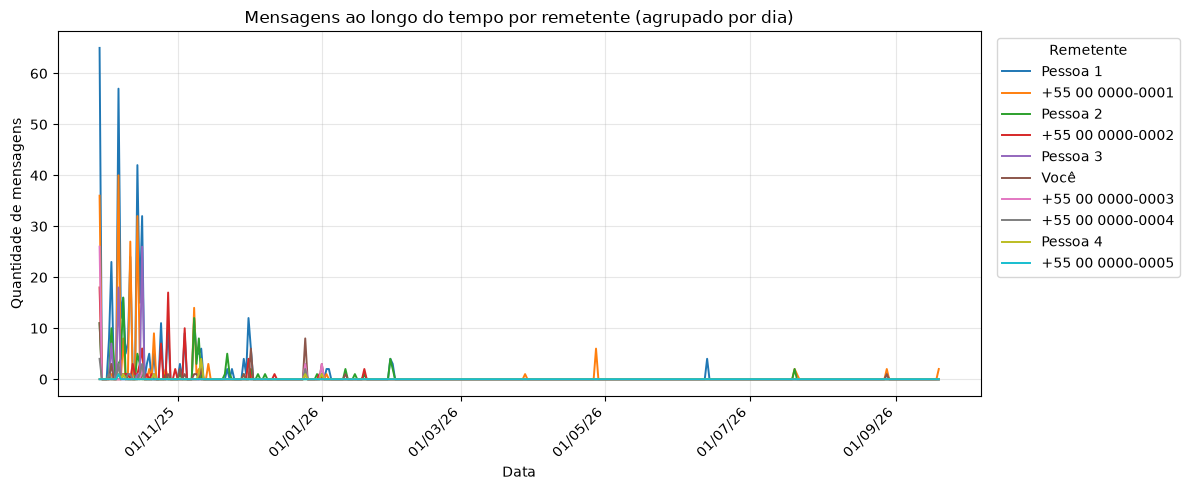

In [10]:
mostrar_figura(grafico_linhas(df, freq="D"))

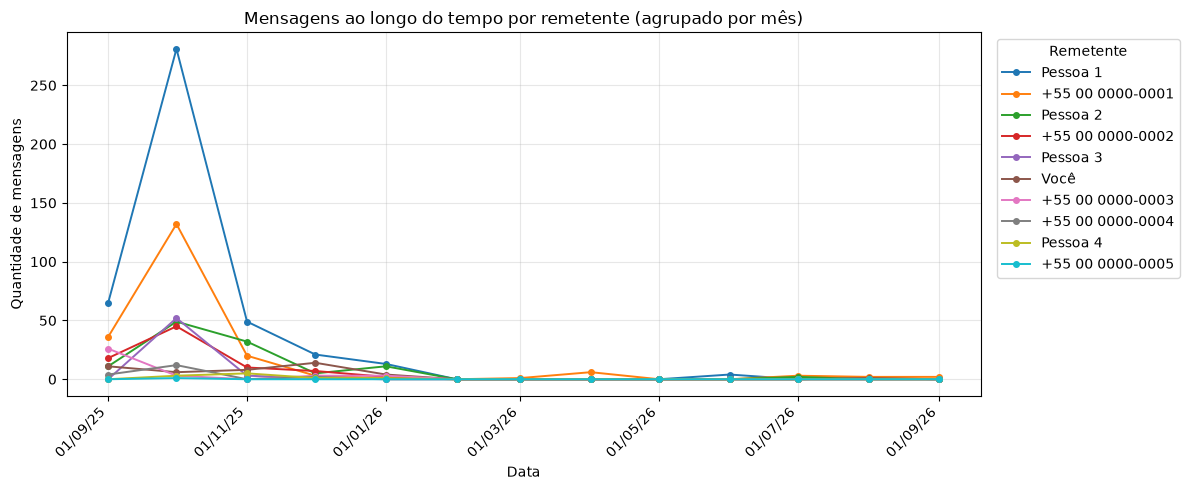

In [11]:
mostrar_figura(grafico_linhas(df, freq="MS"))